In [5]:
# CELL 0 — Install missing packages (run this first every time)
!pip install -q importlib_resources

In [1]:
# CELL 1 — Check that the GPU is switched on
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU found:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# CELL 2 — Connect Google Drive and create the project folders
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT = '/content/drive/MyDrive/capstone'

folders = [
    'my_photos/neither',   # Set 1: your own "neither" photos for TRAINING
    'my_test/dog',         # Set 2: your own TEST photos, sorted by what they really are
    'my_test/cat',
    'my_test/neither',
    'model'                # where the trained model will be saved
]

for f in folders:
    os.makedirs(os.path.join(PROJECT, f), exist_ok=True)

print("Project folder ready:", PROJECT)
print("Inside it:", os.listdir(PROJECT))

Mounted at /content/drive
Project folder ready: /content/drive/MyDrive/capstone
Inside it: ['my_photos', 'my_test', 'model']


In [6]:
# CELL 3 — Download the cat/dog dataset (Oxford-IIIT Pet)
import tensorflow_datasets as tfds

pets_train, info = tfds.load('oxford_iiit_pet', split='train', with_info=True)
pets_test = tfds.load('oxford_iiit_pet', split='test')

print("Species names:", info.features['species'].names)
print("Training photos:", info.splits['train'].num_examples)
print("Test photos:", info.splits['test'].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.BUS36S_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.BUS36S_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
Species names: ['Cat', 'Dog']
Training photos: 3680
Test photos: 3669


In [7]:
# CELL 4 — Count how many cats and dogs we have
species_names = info.features['species'].names   # ['Cat', 'Dog']

def count_species(dataset):
    counts = {name: 0 for name in species_names}
    for example in dataset:
        label_number = int(example['species'])        # 0 or 1
        counts[species_names[label_number]] += 1      # turn 0/1 into 'Cat'/'Dog' and add one
    return counts

print("Training set:", count_species(pets_train))
print("Test set:    ", count_species(pets_test))

Training set: {'Cat': 1188, 'Dog': 2492}
Test set:     {'Cat': 1183, 'Dog': 2486}


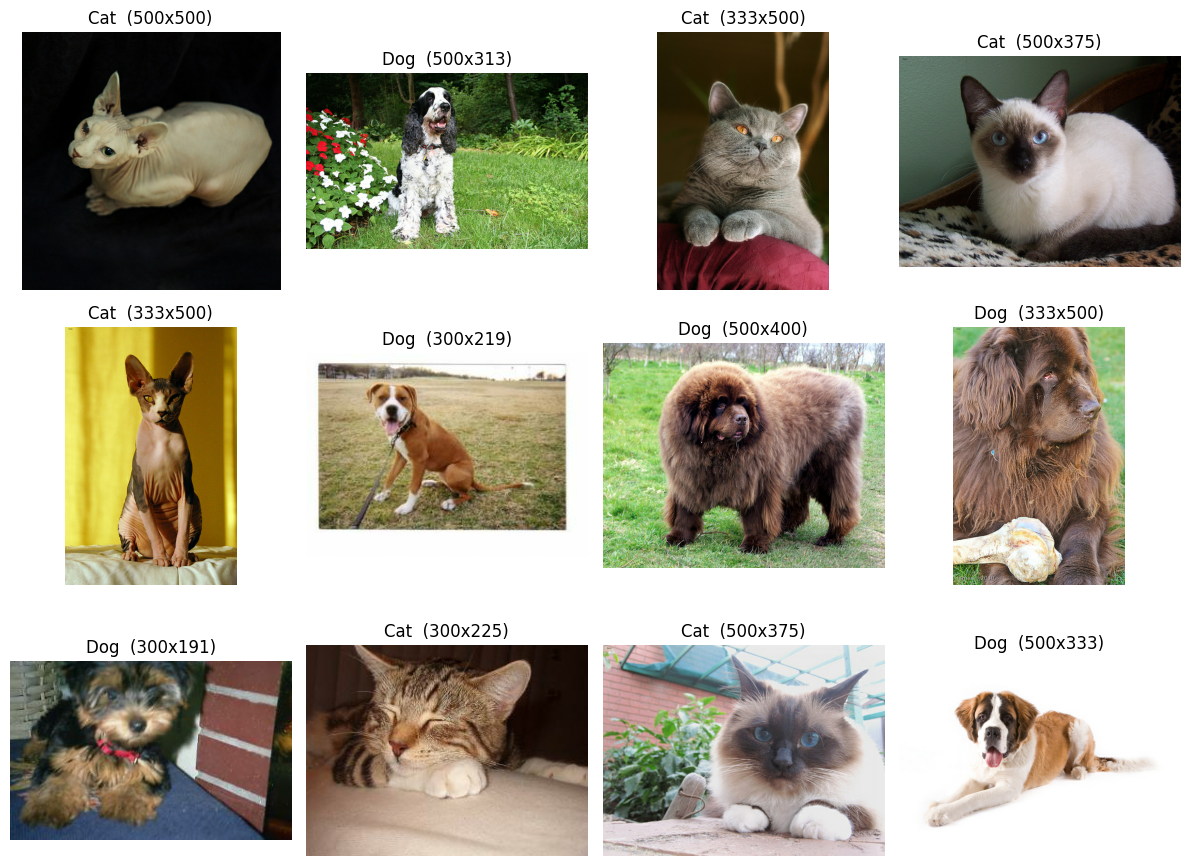

In [8]:
# CELL 5 — Look at the photos: show 12 with their labels
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 9))

for i, example in enumerate(pets_train.take(12)):
    image = example['image'].numpy()
    label = species_names[int(example['species'])]

    plt.subplot(3, 4, i + 1)          # a grid of 3 rows x 4 columns, picture number i+1
    plt.imshow(image)
    plt.title(f"{label}  ({image.shape[1]}x{image.shape[0]})")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [9]:
# CELL 6 — Download Caltech-101 (our "neither" photos) and read its class list
caltech_train, caltech_info = tfds.load('caltech101', split='train', with_info=True)
caltech_test = tfds.load('caltech101', split='test')

caltech_names = caltech_info.features['label'].names

print("Number of classes:", len(caltech_names))
print("Photos:", caltech_info.splits['train'].num_examples, "train +",
      caltech_info.splits['test'].num_examples, "test")
print()
for number, name in enumerate(caltech_names):
    print(f"{number:3d}  {name}")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/caltech101/incomplete.QIIOPY_3.0.2/caltech101-train.tfrecord-[0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/caltech101/incomplete.QIIOPY_3.0.2/caltech101-test.tfrecord-[0-9][0-9][0-9…

Dataset caltech101 downloaded and prepared to /root/tensorflow_datasets/caltech101/3.0.2. Subsequent calls will reuse this data.
Number of classes: 102
Photos: 3060 train + 6084 test

  0  accordion
  1  airplanes
  2  anchor
  3  ant
  4  background_google
  5  barrel
  6  bass
  7  beaver
  8  binocular
  9  bonsai
 10  brain
 11  brontosaurus
 12  buddha
 13  butterfly
 14  camera
 15  cannon
 16  car_side
 17  ceiling_fan
 18  cellphone
 19  chair
 20  chandelier
 21  cougar_body
 22  cougar_face
 23  crab
 24  crayfish
 25  crocodile
 26  crocodile_head
 27  cup
 28  dalmatian
 29  dollar_bill
 30  dolphin
 31  dragonfly
 32  electric_guitar
 33  elephant
 34  emu
 35  euphonium
 36  ewer
 37  faces
 38  faces_easy
 39  ferry
 40  flamingo
 41  flamingo_head
 42  garfield
 43  gerenuk
 44  gramophone
 45  grand_piano
 46  hawksbill
 47  headphone
 48  hedgehog
 49  helicopter
 50  ibis
 51  inline_skate
 52  joshua_tree
 53  kangaroo
 54  ketch
 55  lamp
 56  laptop
 57  leopards


Dropped: {'dalmatian': 67, 'snoopy': 35, 'garfield': 34, 'wild_cat': 34, 'cougar_body': 47, 'cougar_face': 69, 'leopards': 200}
Total dropped: 486
Kept as 'neither': 8658


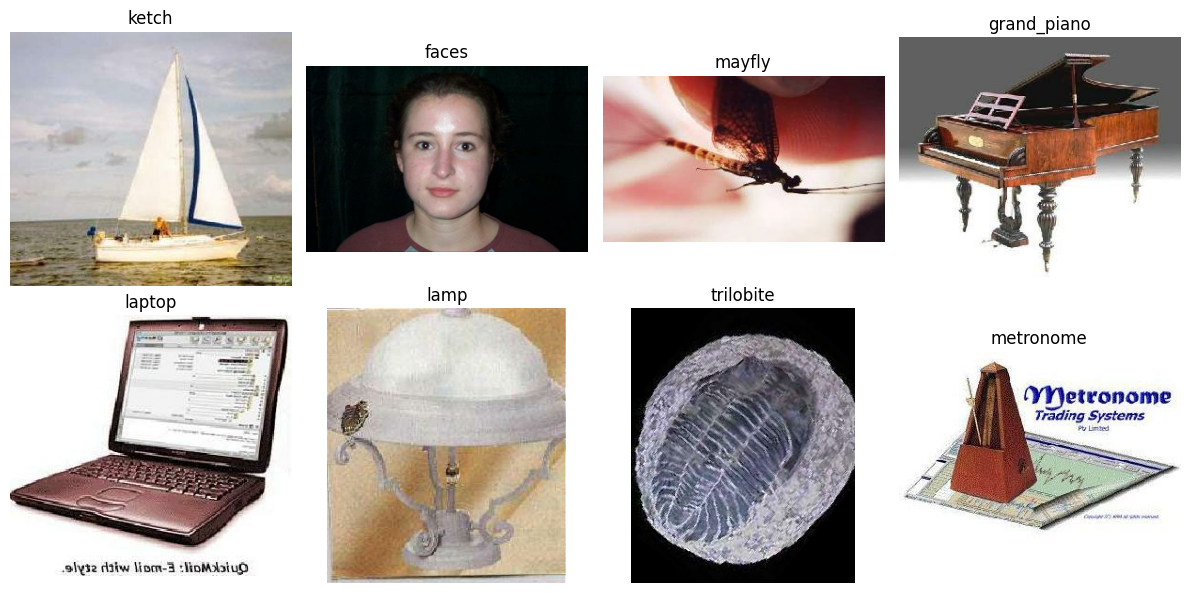

In [10]:
# CELL 7 — Remove the cat-like and dog-like classes from Caltech-101
EXCLUDE = ['dalmatian', 'snoopy', 'garfield', 'wild_cat',
           'cougar_body', 'cougar_face', 'leopards']

# Safety check: stop with a clear message if any name is misspelled
for name in EXCLUDE:
    assert name in caltech_names, f"'{name}' is not in the Caltech list - check spelling"

exclude_numbers = tf.constant([caltech_names.index(n) for n in EXCLUDE], dtype=tf.int64)

def keep_example(example):
    # True only if this photo's label is NOT one of the excluded numbers
    return tf.reduce_all(tf.not_equal(example['label'], exclude_numbers))

caltech_all = caltech_train.concatenate(caltech_test)   # join train + test into one pool
neither_caltech = caltech_all.filter(keep_example)      # keep only the safe photos

# Count what was dropped and what was kept
dropped = {name: 0 for name in EXCLUDE}
kept = 0
for example in caltech_all:
    name = caltech_names[int(example['label'])]
    if name in dropped:
        dropped[name] += 1
    else:
        kept += 1
print("Dropped:", dropped)
print("Total dropped:", sum(dropped.values()))
print("Kept as 'neither':", kept)

# Look at 8 of the kept photos
plt.figure(figsize=(12, 6))
for i, example in enumerate(neither_caltech.shuffle(500).take(8)):
    plt.subplot(2, 4, i + 1)
    plt.imshow(example['image'].numpy())
    plt.title(caltech_names[int(example['label'])])
    plt.axis('off')
plt.tight_layout()
plt.show()

In [11]:
# CELL 8 — Load YOUR OWN "neither" photos from Google Drive
import numpy as np
from PIL import Image, ImageOps

IMG_SIZE = 224   # every image will be resized to 224 x 224 pixels
IMAGE_TYPES = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')

def load_photo(path):
    """Open any photo file and return it the right way up, in normal colour."""
    img = Image.open(path)
    img = ImageOps.exif_transpose(img)   # phones store some photos sideways - this fixes it
    img = img.convert('RGB')             # handles PNGs with transparency and black-and-white photos
    return np.array(img)

def resize_for_model(image):
    """Resize any image to 224x224 without stretching it (adds black bars if needed)."""
    return tf.image.resize_with_pad(tf.cast(image, tf.float32), IMG_SIZE, IMG_SIZE)

def load_folder(folder):
    """Load every photo in a folder. Skip non-photos and broken files instead of crashing."""
    images, names = [], []
    for filename in sorted(os.listdir(folder)):
        if not filename.lower().endswith(IMAGE_TYPES):
            continue
        try:
            images.append(resize_for_model(load_photo(os.path.join(folder, filename))))
            names.append(filename)
        except Exception as error:
            print("Skipped", filename, "-", error)
    return images, names

my_neither_folder = os.path.join(PROJECT, 'my_photos/neither')
my_neither_images, my_neither_names = load_folder(my_neither_folder)
print("Your own 'neither' photos loaded:", len(my_neither_images))

if len(my_neither_images) == 0:
    print("Folder is empty for now - that's OK. Add photos later and re-run this cell.")
else:
    plt.figure(figsize=(12, 6))
    for i in range(min(8, len(my_neither_images))):
        plt.subplot(2, 4, i + 1)
        plt.imshow(my_neither_images[i].numpy().astype('uint8'))
        plt.title(my_neither_names[i][:20])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

Your own 'neither' photos loaded: 0
Folder is empty for now - that's OK. Add photos later and re-run this cell.


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/imagenette/320px-v2/incomplete.RQGOME_1.0.0/imagenette-train.tfrecord-[0-9…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/imagenette/320px-v2/incomplete.RQGOME_1.0.0/imagenette-validation.tfrecord…

Dataset imagenette downloaded and prepared to /root/tensorflow_datasets/imagenette/320px-v2/1.0.0. Subsequent calls will reuse this data.
n01440764 = tench (a fish)
n02102040 = English springer  <-- A DOG, REMOVE
n02979186 = cassette player
n03000684 = chain saw
n03028079 = church
n03394916 = French horn
n03417042 = garbage truck
n03425413 = gas pump
n03445777 = golf ball
n03888257 = parachute

Total Imagenette photos: 9469
Kept as 'neither' (dog removed): 8514


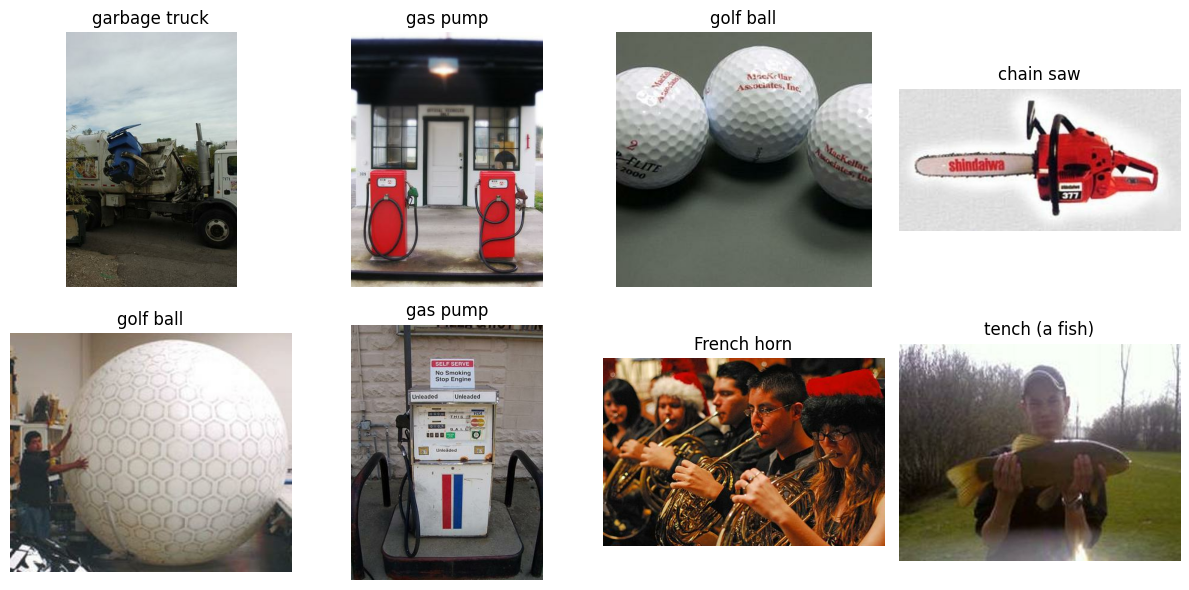

In [12]:
# CELL 9 — Extra real-world "neither" photos: Imagenette
imagenette, imagenette_info = tfds.load('imagenette/320px-v2', split='train', with_info=True)
imagenette_codes = imagenette_info.features['label'].names

# The labels are ImageNet code numbers - here is what each one means
readable = {
    'n01440764': 'tench (a fish)',      'n02102040': 'English springer  <-- A DOG, REMOVE',
    'n02979186': 'cassette player',     'n03000684': 'chain saw',
    'n03028079': 'church',              'n03394916': 'French horn',
    'n03417042': 'garbage truck',       'n03425413': 'gas pump',
    'n03445777': 'golf ball',           'n03888257': 'parachute',
}
for code in imagenette_codes:
    print(code, "=", readable[code])

springer = imagenette_codes.index('n02102040')
neither_imagenette = imagenette.filter(lambda example: example['label'] != springer)

kept = sum(1 for _ in neither_imagenette)
print("\nTotal Imagenette photos:", imagenette_info.splits['train'].num_examples)
print("Kept as 'neither' (dog removed):", kept)

plt.figure(figsize=(12, 6))
for i, example in enumerate(neither_imagenette.shuffle(500).take(8)):
    plt.subplot(2, 4, i + 1)
    plt.imshow(example['image'].numpy())
    plt.title(readable[imagenette_codes[int(example['label'])]])
    plt.axis('off')
plt.tight_layout()
plt.show()

In [19]:
# CELL 10 — Combine everything into one training set and one validation set
CLASS_NAMES = ['dog', 'cat', 'neither']   # same order as the brief's confusion matrix
NEITHER = 2
NEITHER_PER_SOURCE = 1250   # how many training photos to take from Caltech, and from Imagenette
OWN_REPEAT = 10             # each of your own photos is shown 10 times per training round
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def pet_to_pair(example):
    # Oxford says Cat = 0, Dog = 1. We want dog = 0, cat = 1, so we flip it with 1 - species
    label = 1 - tf.cast(example['species'], tf.int32)
    image = tf.cast(resize_for_model(example['image']), tf.uint8)
    return image, label

def neither_to_pair(example):
    image = tf.cast(resize_for_model(example['image']), tf.uint8)
    return image, tf.constant(NEITHER, tf.int32)

def is_training(i, example):
    return i % 5 != 0        # photos 1, 2, 3, 4 of every 5 -> training

def is_validation(i, example):
    return i % 5 == 0        # photo 5 of every 5 -> validation

def drop_number(i, example):
    return example           # throw away the counting number, keep the photo

def split_80_20(dataset):
    numbered = dataset.enumerate()   # give each photo a number: 0, 1, 2, 3...
    train = numbered.filter(is_training).map(drop_number)
    val   = numbered.filter(is_validation).map(drop_number)
    return train, val

caltech_tr, caltech_val = split_80_20(neither_caltech)
imagenette_tr, imagenette_val = split_80_20(neither_imagenette)

# ---- Training pieces ----
train_parts = [
    pets_train.map(pet_to_pair, num_parallel_calls=AUTOTUNE),
    caltech_tr.take(NEITHER_PER_SOURCE).map(neither_to_pair, num_parallel_calls=AUTOTUNE),
    imagenette_tr.take(NEITHER_PER_SOURCE).map(neither_to_pair, num_parallel_calls=AUTOTUNE),
]
if len(my_neither_images) > 0:
    own = tf.data.Dataset.from_tensor_slices(
        (tf.cast(tf.stack(my_neither_images), tf.uint8),
         tf.fill([len(my_neither_images)], NEITHER)))
    train_parts.append(own.repeat(OWN_REPEAT))

# ---- Validation pieces (photos the model never trains on) ----
val_parts = [
    pets_test.take(1500).map(pet_to_pair, num_parallel_calls=AUTOTUNE),
    caltech_val.take(300).map(neither_to_pair, num_parallel_calls=AUTOTUNE),
    imagenette_val.take(300).map(neither_to_pair, num_parallel_calls=AUTOTUNE),
]

def join(parts):
    combined = parts[0]
    for part in parts[1:]:
        combined = combined.concatenate(part)
    return combined

train_examples = join(train_parts).cache()   # .cache() = keep in memory after the first pass
val_examples = join(val_parts).cache()

def count_labels(dataset):
    counts = {name: 0 for name in CLASS_NAMES}
    for _, label in dataset:
        counts[CLASS_NAMES[int(label)]] += 1
    return counts

train_counts = count_labels(train_examples)
val_counts = count_labels(val_examples)
print("Training set:  ", train_counts, " total:", sum(train_counts.values()))
print("Validation set:", val_counts, " total:", sum(val_counts.values()))

def to_float(image, label):
    return tf.cast(image, tf.float32), label

train_ds = (train_examples.shuffle(sum(train_counts.values()))
            .batch(BATCH_SIZE).map(to_float).prefetch(AUTOTUNE))
val_ds = val_examples.batch(BATCH_SIZE).map(to_float).prefetch(AUTOTUNE)
print("Ready: training and validation sets built.")

Training set:   {'dog': 2492, 'cat': 1188, 'neither': 2500}  total: 6180
Validation set: {'dog': 1029, 'cat': 471, 'neither': 600}  total: 2100
Ready: training and validation sets built.


In [20]:
# CELL 11 — Build and train the cat-vs-dog baseline (2 classes)
from tensorflow import keras
from tensorflow.keras import layers

def build_model(num_classes):
    # 1. Random changes to each training photo, so the model sees more variety
    augment = keras.Sequential([
        layers.RandomFlip('horizontal'),    # mirror left-right
        layers.RandomRotation(0.1),         # tilt slightly
        layers.RandomZoom(0.15),            # zoom in or out a little
        layers.RandomContrast(0.2),         # change contrast
        layers.RandomBrightness(0.2),       # darker or brighter (like indoor lighting)
    ], name='augmentation')

    # 2. A model Google already trained on 1.2 million photos - we reuse what it learned
    base = keras.applications.EfficientNetB0(include_top=False, weights='imagenet',
                                             input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False   # "frozen": we do NOT change what it already knows

    # 3. Stack it together, with a small new decision layer on top
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = augment(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)   # the new decision layer

    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

def balanced_weights(counts):
    # Rarer classes get a bigger weight, so the model can't just favour the common one
    total, n = sum(counts), len(counts)
    return {i: total / (n * c) for i, c in enumerate(counts)}

def is_cat_or_dog(image, label):
    return label < NEITHER     # keep labels 0 (dog) and 1 (cat), drop 2 (neither)

two_train = (train_examples.filter(is_cat_or_dog).shuffle(4000)
             .batch(BATCH_SIZE).map(to_float).prefetch(AUTOTUNE))
two_val = (val_examples.filter(is_cat_or_dog)
           .batch(BATCH_SIZE).map(to_float).prefetch(AUTOTUNE))

two_weights = balanced_weights([train_counts['dog'], train_counts['cat']])
print("Class weights (0 = dog, 1 = cat):", two_weights)

baseline = build_model(num_classes=2)
history_2 = baseline.fit(two_train, validation_data=two_val,
                         epochs=5, class_weight=two_weights)

loss, acc = baseline.evaluate(two_val, verbose=0)
print(f"\nBASELINE (cat vs dog) validation accuracy: {acc*100:.1f}%")

Class weights (0 = dog, 1 = cat): {0: 0.7383627608346709, 1: 1.5488215488215489}
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
    115/Unknown 25s 79ms/step - accuracy: 0.8030 - loss: 0.3826

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


115/115 ━━━━━━━━━━━━━━━━━━━━ 35s 164ms/step - accuracy: 0.9133 - loss: 0.2187 - val_accuracy: 0.9900 - val_loss: 0.0760
Epoch 2/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 13s 112ms/step - accuracy: 0.9796 - loss: 0.0788 - val_accuracy: 0.9933 - val_loss: 0.0460
Epoch 3/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 13s 112ms/step - accuracy: 0.9802 - loss: 0.0633 - val_accuracy: 0.9927 - val_loss: 0.0356
Epoch 4/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - accuracy: 0.9796 - loss: 0.0569 - val_accuracy: 0.9933 - val_loss: 0.0303
Epoch 5/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 13s 111ms/step - accuracy: 0.9861 - loss: 0.0464 - val_accuracy: 0.9953 - val_loss: 0.0280

BASELINE (cat vs dog) validation accuracy: 99.5%


Real cats/dogs:   average top confidence 98.0%
'Neither' photos: average top confidence 73.3%
'Neither' photos called cat/dog with OVER 90% confidence: 84 of 600

If we say 'neither' below this cut-off...
Cut-off | 'neither' caught | real pets wrongly thrown out
  0.60  |       23.2%      |        0.3%
  0.70  |       42.7%      |        0.9%
  0.80  |       63.5%      |        2.2%
  0.90  |       86.0%      |        4.7%
  0.95  |       94.5%      |        8.9%
  0.99  |       99.3%      |       32.2%


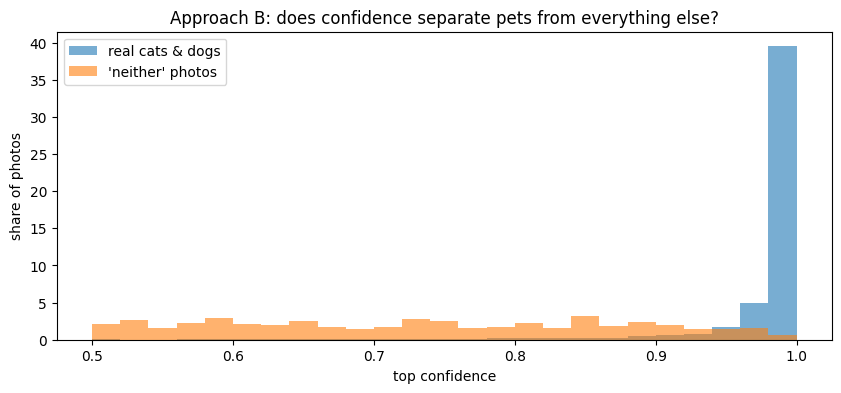

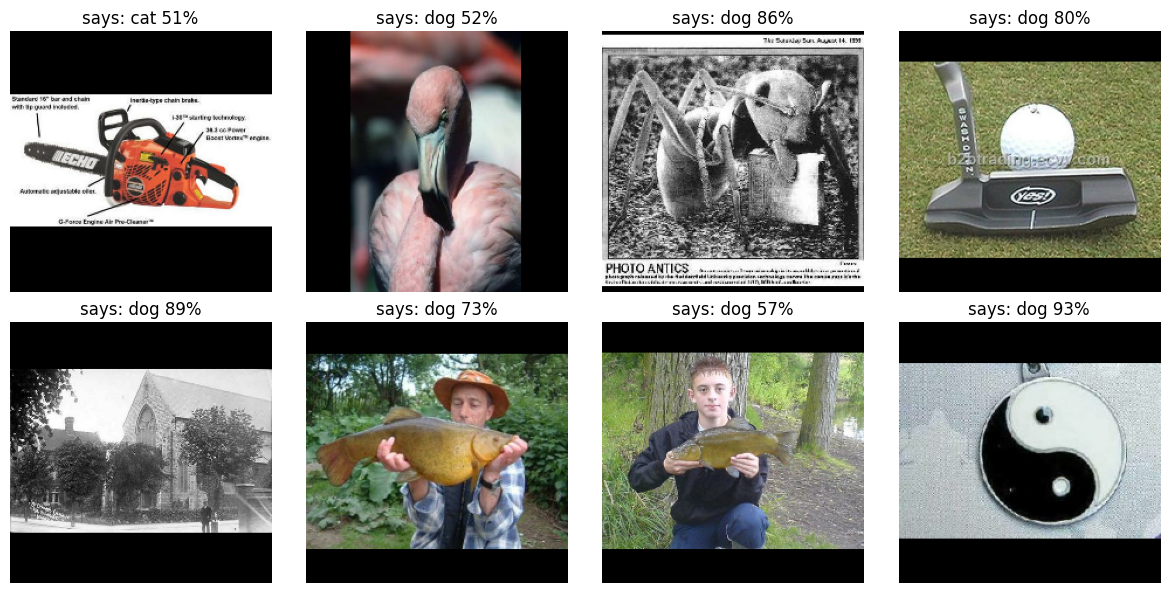

In [21]:
# CELL 12 — Approach B test: can a confidence threshold catch "neither"?
def is_neither(image, label):
    return label == NEITHER

neither_val = val_examples.filter(is_neither).batch(BATCH_SIZE).map(to_float)

pet_probs = baseline.predict(two_val, verbose=0)          # 1,500 real cats and dogs
neither_probs = baseline.predict(neither_val, verbose=0)  # 600 trucks, pianos, faces...

pet_top = pet_probs.max(axis=1)          # the model's top confidence for each photo
neither_top = neither_probs.max(axis=1)

print(f"Real cats/dogs:   average top confidence {pet_top.mean()*100:.1f}%")
print(f"'Neither' photos: average top confidence {neither_top.mean()*100:.1f}%")
print(f"'Neither' photos called cat/dog with OVER 90% confidence: "
      f"{(neither_top > 0.9).sum()} of {len(neither_top)}")

print("\nIf we say 'neither' below this cut-off...")
print("Cut-off | 'neither' caught | real pets wrongly thrown out")
for t in [0.6, 0.7, 0.8, 0.9, 0.95, 0.99]:
    caught = (neither_top < t).mean() * 100
    lost = (pet_top < t).mean() * 100
    print(f"  {t:.2f}  |      {caught:5.1f}%      |      {lost:5.1f}%")

# Chart: how confident is the model on pets vs on everything else?
plt.figure(figsize=(10, 4))
plt.hist(pet_top, bins=25, range=(0.5, 1), density=True, alpha=0.6, label='real cats & dogs')
plt.hist(neither_top, bins=25, range=(0.5, 1), density=True, alpha=0.6, label="'neither' photos")
plt.xlabel('top confidence')
plt.ylabel('share of photos')
plt.title('Approach B: does confidence separate pets from everything else?')
plt.legend()
plt.show()

# Show 8 'neither' photos and what the two-class model said about them
images, _ = next(iter(val_examples.filter(is_neither).shuffle(600, seed=1).batch(8)))
probs = baseline.predict(tf.cast(images, tf.float32), verbose=0)
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy())
    plt.title(f"says: {CLASS_NAMES[probs[i].argmax()]} {probs[i].max()*100:.0f}%")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [22]:
# CELL 13 — Approach A: train the THREE-class model (dog / cat / neither)
three_weights = balanced_weights([train_counts['dog'],
                                  train_counts['cat'],
                                  train_counts['neither']])
print("Class weights (0 = dog, 1 = cat, 2 = neither):", three_weights)

model3 = build_model(num_classes=3)
history_3 = model3.fit(train_ds, validation_data=val_ds,
                       epochs=6, class_weight=three_weights)

loss, acc = model3.evaluate(val_ds, verbose=0)
print(f"\nTHREE-CLASS validation accuracy: {acc*100:.1f}%")

Class weights (0 = dog, 1 = cat, 2 = neither): {0: 0.826645264847512, 1: 1.734006734006734, 2: 0.824}
Epoch 1/6
194/194 ━━━━━━━━━━━━━━━━━━━━ 34s 126ms/step - accuracy: 0.8940 - loss: 0.3188 - val_accuracy: 0.9843 - val_loss: 0.1544
Epoch 2/6
194/194 ━━━━━━━━━━━━━━━━━━━━ 21s 106ms/step - accuracy: 0.9725 - loss: 0.1229 - val_accuracy: 0.9914 - val_loss: 0.0867
Epoch 3/6
194/194 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - accuracy: 0.9751 - loss: 0.0945 - val_accuracy: 0.9900 - val_loss: 0.0696
Epoch 4/6
194/194 ━━━━━━━━━━━━━━━━━━━━ 20s 105ms/step - accuracy: 0.9790 - loss: 0.0735 - val_accuracy: 0.9924 - val_loss: 0.0539
Epoch 5/6
194/194 ━━━━━━━━━━━━━━━━━━━━ 21s 106ms/step - accuracy: 0.9812 - loss: 0.0671 - val_accuracy: 0.9914 - val_loss: 0.0478
Epoch 6/6
194/194 ━━━━━━━━━━━━━━━━━━━━ 20s 105ms/step - accuracy: 0.9846 - loss: 0.0565 - val_accuracy: 0.9943 - val_loss: 0.0396

THREE-CLASS validation accuracy: 99.4%


FAIR COMPARISON (same validation photos, same cost to real pets)
Approach A - three classes      : catches  99.3% of 'neither', wrongly throws out  0.0% of real pets
Approach B - cut-off at 0.514: catches   3.2% of 'neither', wrongly throws out  0.0% of real pets


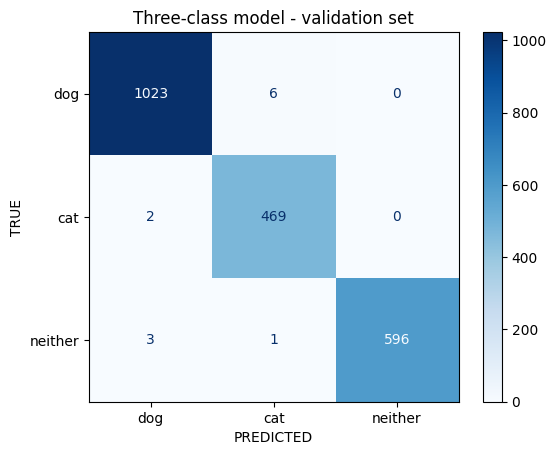

              precision    recall  f1-score   support

         dog      0.995     0.994     0.995      1029
         cat      0.985     0.996     0.990       471
     neither      1.000     0.993     0.997       600

    accuracy                          0.994      2100
   macro avg      0.993     0.994     0.994      2100
weighted avg      0.994     0.994     0.994      2100

Validation photos it got wrong: 12 of 2100


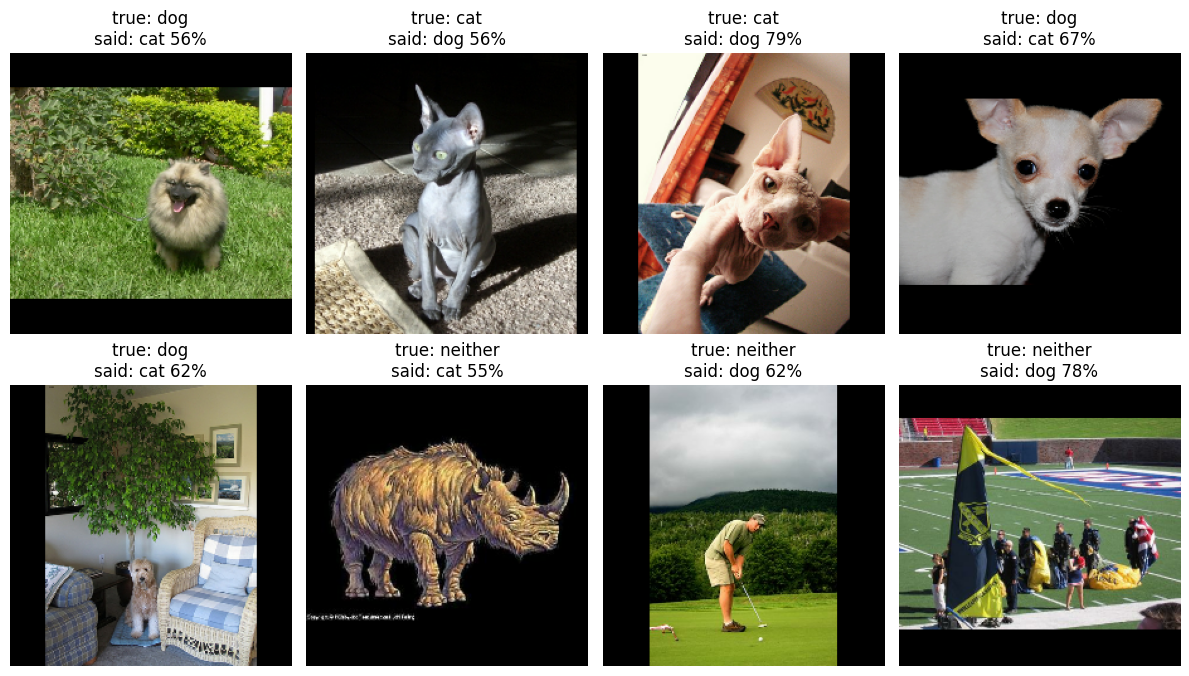

In [23]:
# CELL 14 — Compare Approach A vs B, and draw the validation confusion matrix
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# What each validation photo really is, and what the three-class model said
true_labels = np.concatenate([labels.numpy() for _, labels in val_ds])
probs3 = model3.predict(val_ds, verbose=0)
pred3 = probs3.argmax(axis=1)     # the class with the highest score

is_pet = true_labels < NEITHER
is_neither_photo = true_labels == NEITHER

# ---- Approach A: the three-class model ----
a_caught = (pred3[is_neither_photo] == NEITHER).mean() * 100
a_lost = (pred3[is_pet] == NEITHER).mean() * 100

# ---- Approach B: the threshold, set so it throws out the SAME share of real pets as A ----
cutoff = np.quantile(pet_top, a_lost / 100) if a_lost > 0 else pet_top.min()
b_caught = (neither_top < cutoff).mean() * 100
b_lost = (pet_top < cutoff).mean() * 100

print("FAIR COMPARISON (same validation photos, same cost to real pets)")
print(f"Approach A - three classes      : catches {a_caught:5.1f}% of 'neither', "
      f"wrongly throws out {a_lost:4.1f}% of real pets")
print(f"Approach B - cut-off at {cutoff:.3f}: catches {b_caught:5.1f}% of 'neither', "
      f"wrongly throws out {b_lost:4.1f}% of real pets")

# ---- Confusion matrix (same layout as the brief: rows = TRUE, columns = PREDICTED) ----
cm = confusion_matrix(true_labels, pred3, labels=[0, 1, 2])
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap='Blues', values_format='d')
plt.title('Three-class model - validation set')
plt.xlabel('PREDICTED')
plt.ylabel('TRUE')
plt.show()

print(classification_report(true_labels, pred3, target_names=CLASS_NAMES, digits=3))

# ---- Show up to 8 photos it got wrong ----
wrong = np.where(pred3 != true_labels)[0]
print(f"Validation photos it got wrong: {len(wrong)} of {len(true_labels)}")
if len(wrong) > 0:
    pick = set(np.random.default_rng(0).choice(wrong, min(8, len(wrong)), replace=False).tolist())
    plt.figure(figsize=(12, 7))
    k = 0
    for idx, (image, label) in enumerate(val_examples):
        if idx in pick:
            k += 1
            plt.subplot(2, 4, k)
            plt.imshow(image.numpy())
            plt.title(f"true: {CLASS_NAMES[int(label)]}\n"
                      f"said: {CLASS_NAMES[pred3[idx]]} {probs3[idx].max()*100:.0f}%")
            plt.axis('off')
        if k == len(pick):
            break
    plt.tight_layout()
    plt.show()


In [24]:
# CELL 16 — Save the model to Google Drive, then prove it reloads
import json

MODEL_PATH = os.path.join(PROJECT, 'model', 'cat_dog_neither.keras')
model3.save(MODEL_PATH)

with open(os.path.join(PROJECT, 'model', 'class_names.json'), 'w') as f:
    json.dump(CLASS_NAMES, f)

print("Saved to:", MODEL_PATH)
print(f"File size: {os.path.getsize(MODEL_PATH) / 1e6:.1f} MB")

# Load it back from Drive and check it gives the SAME answers as the model in memory
reloaded = keras.models.load_model(MODEL_PATH)
original_answers = model3.predict(val_ds.take(1), verbose=0)
reloaded_answers = reloaded.predict(val_ds.take(1), verbose=0)
print("Reloaded model gives the same answers:",
      np.allclose(original_answers, reloaded_answers, atol=1e-5))

Saved to: /content/drive/MyDrive/capstone/model/cat_dog_neither.keras
File size: 17.1 MB


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


Reloaded model gives the same answers: True
